In [1]:
# =============================================
#                   IMPORT
# =============================================
from keras.optimizers                   import Adam
from keras.callbacks                    import EarlyStopping, ReduceLROnPlateau
from preProcessingData                  import PreProcessData
from model.systemModel                  import SystemModel
from model.systemModel                  import SubclassModelCheckpoint

from tqdm                               import tqdm
from datetime                           import datetime
import tensorflow                       as tf
import numpy                            as np 
import matplotlib.pyplot                as plt
import os, warnings
import random
import json


# ====================================
# Set debug level and 
# ------------------------------------
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

# ====================================
# Config
# ------------------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["system"]

2024-11-11 12:02:19.070766: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-11-11 12:02:19.213314: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-11-11 12:02:19.847609: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2024-11-11 12:02:19.847686: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerro

In [2]:
preData     = PreProcessData(config = myConfig)                    # Preprocessing data
rawData                         = preData.loadCriticalData()                           # Load the data from critical file
addedTimeData                   = preData.addFloatTimeOld(rawData)                        # Add the time to the data
cleanedData                     = preData.cleanData(addedTimeData, headline = preData.crusher1Value)
addedData                       = preData.addition_var(cleanedData) 
normalizedAllData               = preData.normalizeBuilinFunction(addedData, headline = preData.crusher1Value)  

effTraj , cycleTraj    = preData.extractTrajectory(data           = normalizedAllData, 
                                                            headline       = [preData.crusher1Value,'hours'],
                                                            mergeInAList   = True)



Process:25574||2024-11-11 12:02:21,384-INFO [preProcessingData.py:loadCriticalData():376]:Loading critical MOF data from files ...
Process:25574||2024-11-11 12:02:21,746-INFO [preProcessingData.py:loadCriticalData():382]:Finish loading data from files ...
Process:25574||2024-11-11 12:02:23,422-INFO [preProcessingData.py:normalizeBuilinFunction():1114]:Normalizing the data ....


In [3]:
model       = SystemModel(myConfig)   
model.build(input_shape=[(None, myConfig["seqLength"], myConfig["inFeatureDim"]), (None,myConfig["seqLength"], 6)])  # Batch size is None, feature size is 32()
model.summary()
model.load_weights(model_dir = "checkpoint/bestModel")

2024-11-11 12:02:24.197861: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-11-11 12:02:24.198063: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-11-11 12:02:24.204002: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-11-11 12:02:24.204203: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-11-11 12:02:24.204410: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from S

Model: "system_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection (SensorSel  multiple                 0 (unused)
 ection)                                                         
                                                                 
 encoder (Functional)        [(None, 1),               45062     
                              (None, 1, 5)]                      
                                                                 
 decoder (Functional)        (None, 30, 32)            1028864   
                                                                 
Total params: 1,073,967
Trainable params: 1,073,958
Non-trainable params: 9
_________________________________________________________________


Process:25574||2024-11-11 12:02:25,508-INFO [systemModel.py:load_weights():680]:Loading the model at the direction: checkpoint/bestModel
Process:25574||2024-11-11 12:02:25,540-INFO [systemModel.py:load_weights():690]:Loaded the model at the direction:checkpoint/bestModel successfully!!!


In [4]:
zAll= []
# trajectID = trajectID.astype(int)
for idx in range(len(effTraj)):
    if len(effTraj[idx]) < preData.config['seqLength']:
        continue
    # trajectory          = effTraj[trajectID.values == (idx + 1)]                                   # Extract tracjectory from ID
    # print(trajectory.shape)
    # componentTrajectory = trajectory.reset_index(drop = True)                                   # Reset the index of pandas                          

    # if len(componentTrajectory) < preData.config['seqLength']:
    #     continue
    seqEff         = preData.getTensorData(dataList         = [effTraj], 
                                                             seqLength  = preData.config['seqLength'], 
                                                             overlap    = preData.config['seqLength']-1,
                                                             getAtIdx   = idx + 1,
                                                             typeInput  = "listOfList")
    
    hi = model.getHIandRUL([seqEff])
    zAll.append(hi)

Process:25574||2024-11-11 12:02:25,548-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
2024-11-11 12:02:26.602641: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2024-11-11 12:02:27.445915: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-11-11 12:02:27.446379: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-11-11 12:02:27.446404: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-11-11 12:02:27.446845: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-11-11 12:02:27.446908: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to cust

(5006, 1)


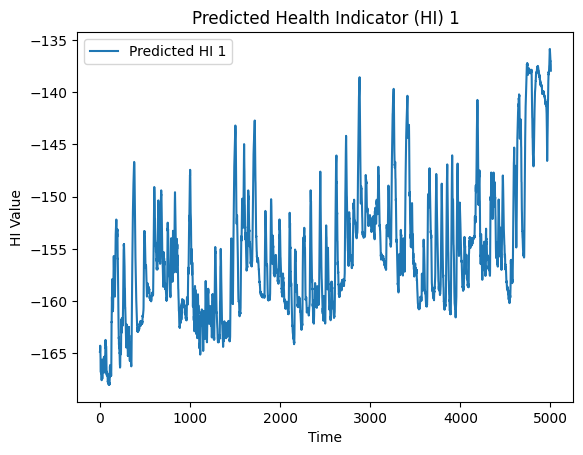

(584, 1)


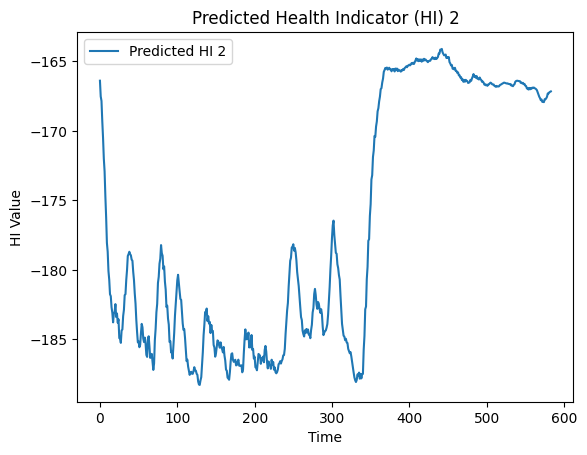

(9659, 1)


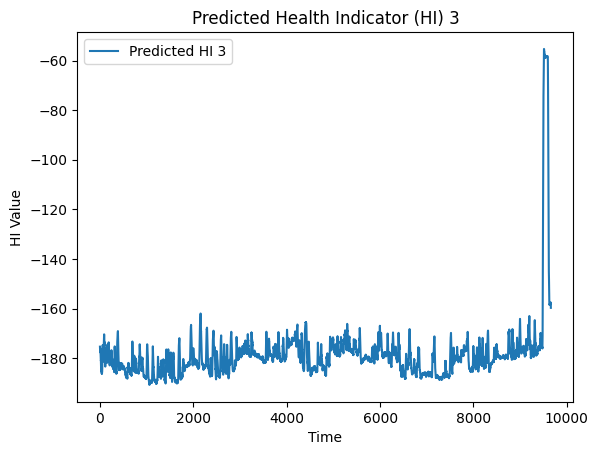

(3035, 1)


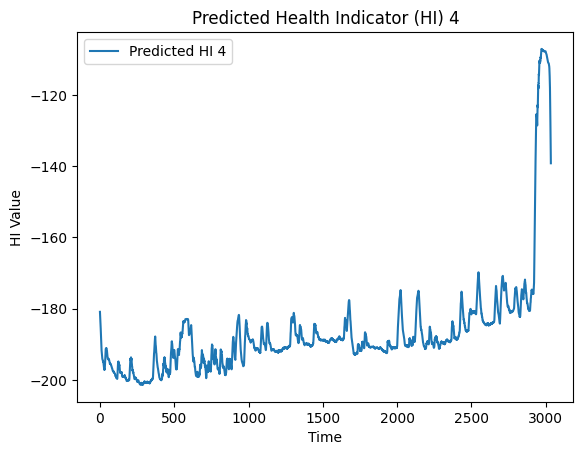

(5792, 1)


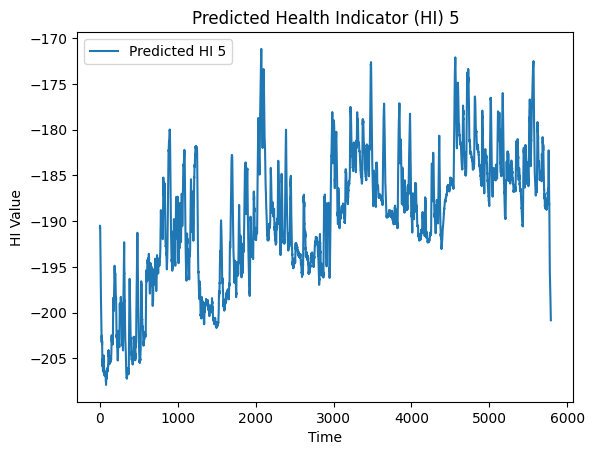

(31, 1)


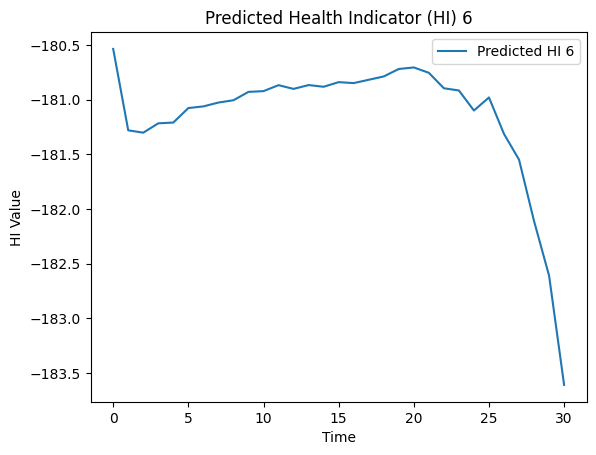

(3507, 1)


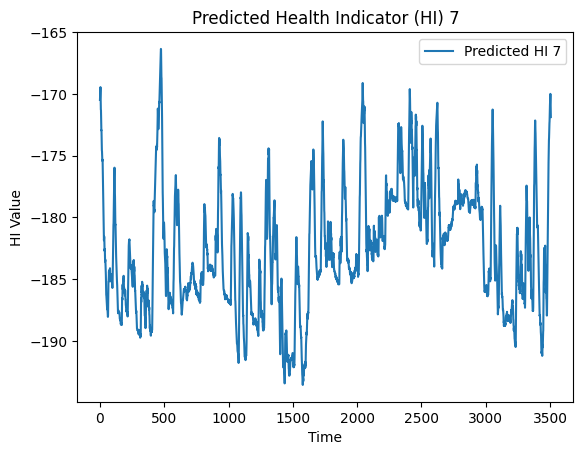

(794, 1)


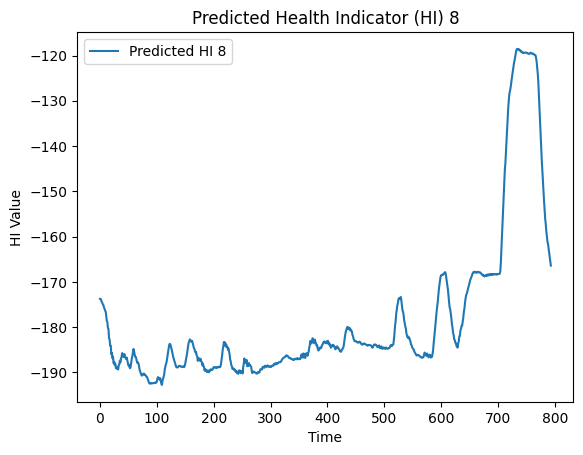

(9503, 1)


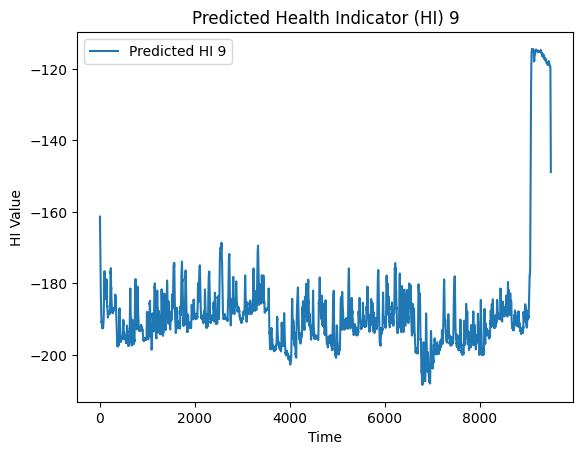

(911, 1)


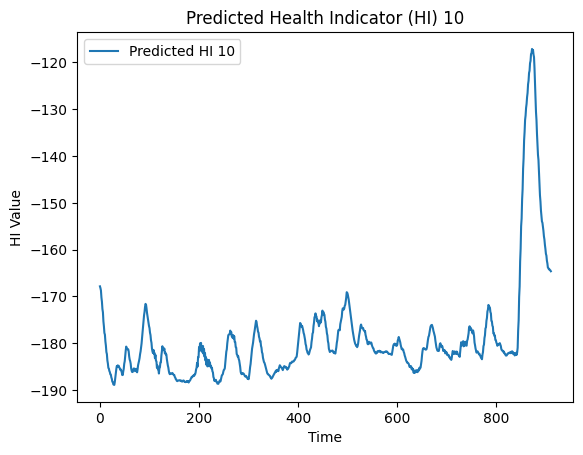

(10256, 1)


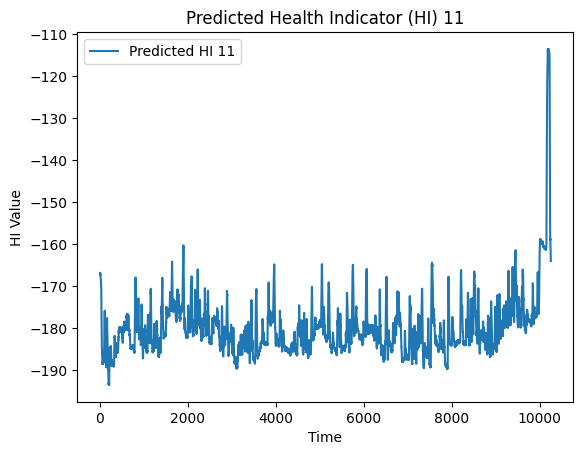

(6378, 1)


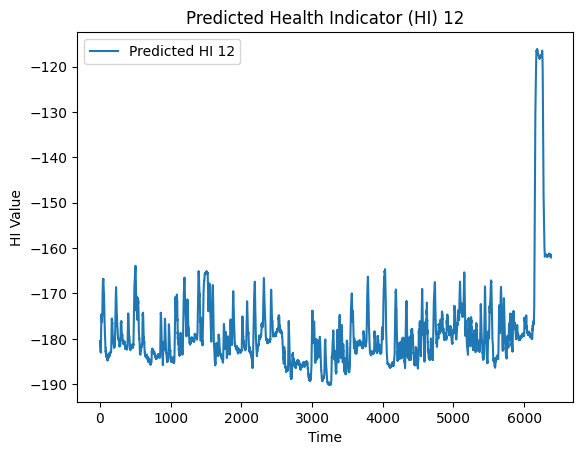

(1461, 1)


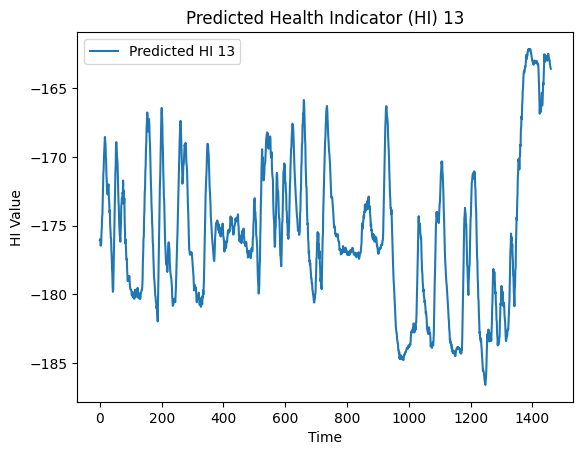

(35, 1)


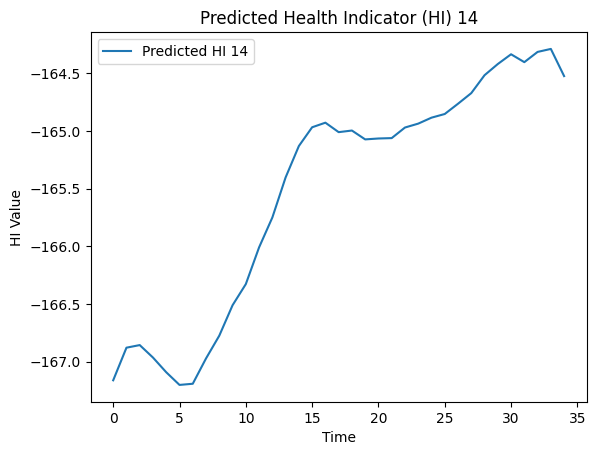

(24500, 1)


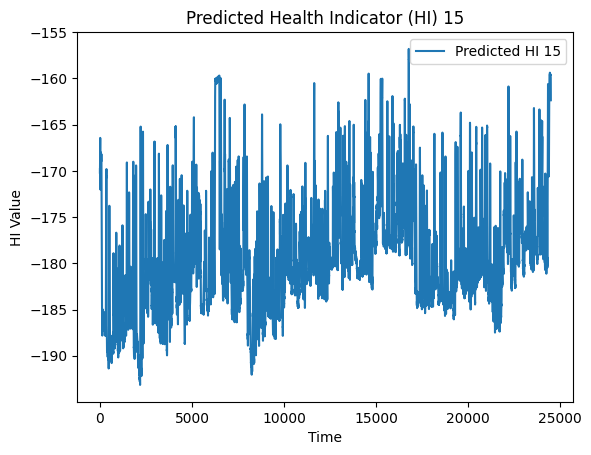

(189, 1)


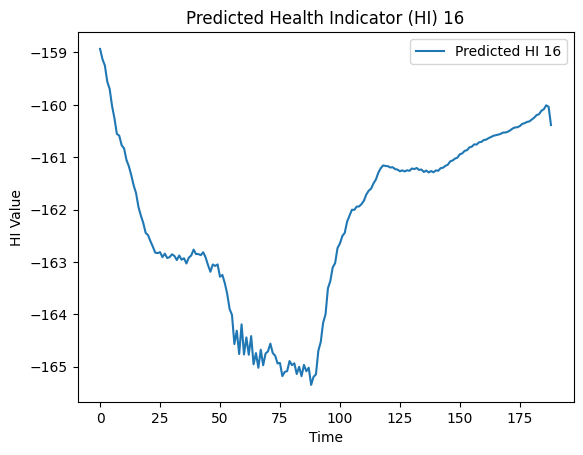

(6374, 1)


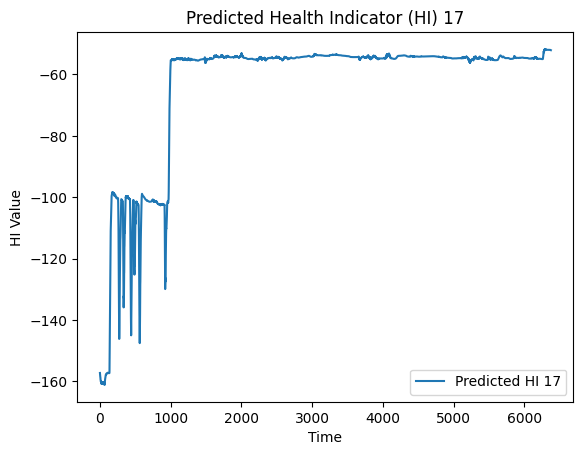

In [5]:
for i, z in enumerate(zAll):
    print(z.shape)
    plt.figure()
    plt.plot(z, label=f'Predicted HI {i+1}')
    plt.title(f'Predicted Health Indicator (HI) {i+1}')
    plt.xlabel('Time')
    plt.ylabel('HI Value')
    plt.legend()
    plt.show()
